# RQ10 — VAL under Low-N: evidence scarcity, metric fragility, and defensible generalization

## Scientific question

**How much of the apparent instability of virion-associated lytic enzyme (VAL) prediction is attributable to sparse positive evidence after stringent sequence control, and which conclusions remain defensible when only a few positive proteins support evaluation?**

VAL is intentionally retained in the benchmark despite becoming Low-N after redundancy reduction and homology-aware partitioning. Low positive support is a property of the available biological evidence space and must be exposed rather than hidden.

RQ10 therefore treats VAL as an **evidence-limited stress test** rather than simply another subtype classifier.

### Primary analysis

Binary subtype task:

`subtype_val`

### Secondary analysis

VAL as one class inside:

`multiclass_clean`

### Core distinction

RQ10 separates two forms of scarcity:

- **learning scarcity** — few positive VAL proteins in outer train;
- **evaluation scarcity** — few positive VAL proteins in outer test.

These are related but not equivalent.

## Scope

RQ10 asks:

1. How many VAL positives and positive homology clusters remain in train/test across all 16 R×S cells?
2. What is the metric resolution implied by those absolute counts?
3. Does model performance change systematically with positive train support?
4. Does apparent performance volatility increase when positive test support is small?
5. Are MCC and ranking metrics similarly support-sensitive?
6. Do stronger representations partially rescue Low-N VAL prediction?
7. Does classifier dependence increase as evidence becomes sparse?
8. Are individual VAL positives consistently recognized across models, or does prediction depend strongly on model choice?
9. Is the same evidence limitation visible for VAL inside the multiclass task?
10. How unusual is VAL relative to endolysin and depolymerase support regimes?

### Explicit exclusions

- No model retraining.
- No repeated-seed experiment.
- No full bootstrap confidence intervals here; those belong to RQ17.
- No common-test R/S decomposition here; that belongs to RQ16.
- No causal claim that Low-N alone explains every VAL effect.

## Interpretation guardrails

- Absolute positive counts must accompany all VAL rates.
- R/S native test sets differ; support-performance associations across cells are descriptive.
- Support values are repeated across the 20 model families inside each R/S cell. Therefore **primary support associations are calculated on 16 unique R×S cells**, not on 320 pseudo-replicated model rows.
- Positive cluster counts are reported alongside positive sequence counts because sequence count and independent homology-component support are not equivalent.
- A Low-N metric can be numerically high and still be weakly resolved.
- T30 rescue under Low-N is evidence of representation value, not proof of a specific biological mechanism.

In [1]:
from pathlib import Path
import math
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)

pd.set_option("display.max_columns", 400)
pd.set_option("display.width", 240)
pd.set_option("display.max_rows", 400)

R_LEVELS = [90, 70, 50, 30]
S_LEVELS = [90, 70, 50, 30]

VAL_TASK = "subtype_val"
MULTI_TASK = "multiclass_clean"

SUBTYPE_TASKS = [
    "subtype_endolysin",
    "subtype_depolymerase",
    "subtype_val",
]

TASK_PATHS = {
    "subtype_endolysin": "subtype_binary/endolysin",
    "subtype_depolymerase": "subtype_binary/depolymerase",
    "subtype_val": "subtype_binary/virion_associated_lytic_enzyme",
    "multiclass_clean": "multiclass_clean",
}

T6 = "esm2_t6_8m"
T30 = "esm2_t30_150m"
ONEHOT = "onehot_1024"
ROXY = "roxy_48"

def find_project_root(start=None):
    start = Path.cwd() if start is None else Path(start)
    for candidate in [start, *start.parents]:
        if (
            (candidate / "results/analysis_supervised/stage12a").is_dir()
            and (candidate / "results/training_supervised").is_dir()
            and (candidate / "data/predictive_universe").is_dir()
        ):
            return candidate
    raise FileNotFoundError(
        "Could not locate project root containing Stage12A, "
        "training_supervised, and predictive_universe."
    )

ROOT = find_project_root()
STAGE12A = ROOT / "results/analysis_supervised/stage12a"
TRAINING_ROOT = ROOT / "results/training_supervised"
PREDICTIVE_ROOT = ROOT / "data/predictive_universe"
CACHE_DIR = ROOT / "results/analysis_supervised/notebook_cache"
CACHE_DIR.mkdir(parents=True, exist_ok=True)

print("ROOT:", ROOT)

ROOT: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass


In [2]:
master = pd.read_csv(
    STAGE12A / "supervised_master_results.tsv",
    sep="\t",
    low_memory=False,
)

val_master = master[
    master["task"].eq(VAL_TASK)
].copy()

multi_master = master[
    master["task"].eq(MULTI_TASK)
].copy()

REPS = sorted(val_master["representation"].unique())
ALGORITHMS = sorted(val_master["algorithm"].unique())

print("VAL experiment families:", len(val_master))
print("Expected:", 16 * len(REPS) * len(ALGORITHMS))
print("Representations:", REPS)
print("Algorithms:", ALGORITHMS)

assert len(val_master) == 16 * len(REPS) * len(ALGORITHMS)

cell_coverage = (
    val_master.groupby(["R", "S"])
    .size()
    .rename("n_models")
    .reset_index()
)

display(cell_coverage)

assert cell_coverage["n_models"].eq(len(REPS) * len(ALGORITHMS)).all()

VAL experiment families: 320
Expected: 320
Representations: ['esm2_t30_150m', 'esm2_t6_8m', 'onehot_1024', 'roxy_48']
Algorithms: ['KNN', 'LR', 'MLP', 'RF', 'XGB']


,R,S,n_models
0,30,30,20
1,30,50,20
2,30,70,20
3,30,90,20
4,50,30,20
5,50,50,20
6,50,70,20
7,50,90,20
8,70,30,20
9,70,50,20


# 1. Locate the frozen eligible-entity tables

**Schema note.** The notebook accepts both the current `split` column and the older contract name `outer_split`; it also accepts common cluster-column aliases.

In [3]:
TASK_ALIASES = {
    "subtype_endolysin": [
        "subtype_endolysin",
        "subtype_binary/endolysin",
        "endolysin",
    ],
    "subtype_depolymerase": [
        "subtype_depolymerase",
        "subtype_binary/depolymerase",
        "depolymerase",
    ],
    "subtype_val": [
        "subtype_val",
        "subtype_binary/virion_associated_lytic_enzyme",
        "virion_associated_lytic_enzyme",
    ],
    "multiclass_clean": [
        "multiclass_clean",
    ],
}

def candidate_eligible_paths(task, r, s):
    paths = []
    for alias in TASK_ALIASES.get(task, [task]):
        paths.append(
            PREDICTIVE_ROOT
            / alias
            / f"R{r}_S{s}"
            / "eligible_entities.tsv.gz"
        )
    return paths

def resolve_eligible_path(task, r, s):
    for p in candidate_eligible_paths(task, r, s):
        if p.is_file():
            return p

    # Conservative recursive fallback.
    rs_token = f"R{r}_S{s}"
    hits = [
        p for p in PREDICTIVE_ROOT.rglob("eligible_entities.tsv.gz")
        if rs_token in p.parts
    ]

    task_tokens = {
        token.lower()
        for alias in TASK_ALIASES.get(task, [task])
        for token in alias.split("/")
    }

    scored = []
    for p in hits:
        path_text = str(p).lower()
        score = sum(token in path_text for token in task_tokens)
        if score:
            scored.append((score, p))

    if scored:
        scored.sort(key=lambda x: (-x[0], str(x[1])))
        return scored[0][1]

    raise FileNotFoundError(
        f"No eligible_entities.tsv.gz found for {task} R{r}_S{s}"
    )

resolved_examples = []
for task in [VAL_TASK, MULTI_TASK]:
    for r, s in [(90, 90), (30, 30)]:
        p = resolve_eligible_path(task, r, s)
        resolved_examples.append((task, r, s, str(p)))

display(
    pd.DataFrame(
        resolved_examples,
        columns=["task", "R", "S", "path"],
    )
)

,task,R,S,path
0,subtype_val,90,90,/home/david/Desktop/colabs/inta_project/phagel...
1,subtype_val,30,30,/home/david/Desktop/colabs/inta_project/phagel...
2,multiclass_clean,90,90,/home/david/Desktop/colabs/inta_project/phagel...
3,multiclass_clean,30,30,/home/david/Desktop/colabs/inta_project/phagel...


# 2. Helpers for split, binary label, and VAL class detection

In [4]:
def normalize_split(series):
    s = series.astype(str).str.strip().str.lower()
    return s

def infer_split_column(df):
    # Current Stage-10E artifacts use `split`; older contracts used `outer_split`.
    for c in ["split", "outer_split", "partition", "set"]:
        if c in df.columns:
            return c
    raise KeyError(
        f"No split column found. Available columns: {list(df.columns)}"
    )

def infer_cluster_column(df):
    for c in ["cluster_id", "mmseqs_cluster_id", "cluster"]:
        if c in df.columns:
            return c
    return None

def binary_positive_mask(series):
    numeric = pd.to_numeric(series, errors="coerce")

    if numeric.notna().any():
        # Frozen binary convention is 0/1.
        return numeric.eq(1)

    s = series.astype(str).str.strip().str.lower()
    positive_values = {
        "1",
        "positive",
        "pos",
        "p",
        "true",
        "yes",
        "val",
        "virion_associated_lytic_enzyme",
        "virion-associated lytic enzyme",
    }
    return s.isin(positive_values)

def val_class_mask(df):
    for c in ["class_name", "class", "target_class", "label_name"]:
        if c in df.columns:
            s = (
                df[c]
                .astype(str)
                .str.strip()
                .str.lower()
                .str.replace("-", "_", regex=False)
                .str.replace(" ", "_", regex=False)
            )
            mask = (
                s.str.contains("virion", na=False)
                & s.str.contains("lytic", na=False)
            ) | s.isin({"val", "virion_associated_lytic_enzyme"})
            if mask.any():
                return mask, c

    # Last fallback only if labels are human-readable.
    if "label" in df.columns:
        s = df["label"].astype(str).str.lower()
        mask = s.str.contains("virion", na=False)
        if mask.any():
            return mask, "label"

    raise KeyError(
        "Could not identify the VAL class in multiclass eligible entities."
    )

# 3. Exact binary VAL support across the 16 R×S cells

In [5]:
support_rows = []

for r in R_LEVELS:
    for s in S_LEVELS:
        path = resolve_eligible_path(VAL_TASK, r, s)
        df = pd.read_csv(path, sep="\t", low_memory=False)

        if "label" not in df.columns:
            raise KeyError(
                f"{path}: missing label column. Available columns: {list(df.columns)}"
            )

        split_col = infer_split_column(df)
        cluster_col = infer_cluster_column(df)

        split = normalize_split(df[split_col])
        pos = binary_positive_mask(df["label"])

        train = split.eq("train")
        test = split.eq("test")

        row = {
            "task": VAL_TASK,
            "R": r,
            "S": s,
            "n_train": int(train.sum()),
            "n_test": int(test.sum()),
            "n_positive_train": int((train & pos).sum()),
            "n_positive_test": int((test & pos).sum()),
            "n_negative_train": int((train & ~pos).sum()),
            "n_negative_test": int((test & ~pos).sum()),
        }

        row["train_prevalence"] = (
            row["n_positive_train"] / row["n_train"]
            if row["n_train"] else np.nan
        )
        row["test_prevalence"] = (
            row["n_positive_test"] / row["n_test"]
            if row["n_test"] else np.nan
        )

        row["one_positive_recall_step"] = (
            1.0 / row["n_positive_test"]
            if row["n_positive_test"] else np.nan
        )

        if cluster_col:
            row["n_positive_train_clusters"] = int(
                df.loc[train & pos, cluster_col].nunique()
            )
            row["n_positive_test_clusters"] = int(
                df.loc[test & pos, cluster_col].nunique()
            )
            row["positive_test_entities_per_cluster"] = (
                row["n_positive_test"]
                / row["n_positive_test_clusters"]
                if row["n_positive_test_clusters"] else np.nan
            )

        support_rows.append(row)

val_support = pd.DataFrame(support_rows)

display(val_support)

,task,R,S,n_train,n_test,n_positive_train,n_positive_test,n_negative_train,n_negative_test,train_prevalence,test_prevalence,one_positive_recall_step,n_positive_train_clusters,n_positive_test_clusters,positive_test_entities_per_cluster
0,subtype_val,90,90,19117,8192,63,26,19054,8166,0.003295,0.003174,0.038462,63,26,1.000000
1,subtype_val,90,70,19112,8197,67,22,19045,8175,0.003506,0.002684,0.045455,58,22,1.000000
2,subtype_val,90,50,19110,8199,68,21,19042,8178,0.003558,0.002561,0.047619,46,19,1.105263
3,subtype_val,90,30,19108,8201,75,14,19033,8187,0.003925,0.001707,0.071429,36,12,1.166667
4,subtype_val,70,90,13690,5865,59,21,13631,5844,0.004310,0.003581,0.047619,59,21,1.000000
5,subtype_val,70,70,13694,5861,59,21,13635,5840,0.004308,0.003583,0.047619,59,21,1.000000
6,subtype_val,70,50,13677,5878,55,25,13622,5853,0.004021,0.004253,0.040000,45,20,1.250000
7,subtype_val,70,30,13661,5894,48,32,13613,5862,0.003514,0.005429,0.031250,32,16,2.000000
8,subtype_val,50,90,9467,4066,46,18,9421,4048,0.004859,0.004427,0.055556,46,18,1.000000
9,subtype_val,50,70,9477,4056,46,18,9431,4038,0.004854,0.004438,0.055556,46,18,1.000000


In [6]:
print("VAL positive train support")
display(
    val_support.pivot(
        index="R",
        columns="S",
        values="n_positive_train",
    ).reindex(index=R_LEVELS, columns=S_LEVELS)
)

print("VAL positive test support")
display(
    val_support.pivot(
        index="R",
        columns="S",
        values="n_positive_test",
    ).reindex(index=R_LEVELS, columns=S_LEVELS)
)

if "n_positive_test_clusters" in val_support.columns:
    print("VAL positive test homology-cluster support")
    display(
        val_support.pivot(
            index="R",
            columns="S",
            values="n_positive_test_clusters",
        ).reindex(index=R_LEVELS, columns=S_LEVELS)
    )

VAL positive train support


S,90,70,50,30
R,,,,
90,63,67,68,75
70,59,59,55,48
50,46,46,46,46
30,31,31,31,31


VAL positive test support


S,90,70,50,30
R,,,,
90,26,22,21,14
70,21,21,25,32
50,18,18,18,18
30,17,17,17,17


VAL positive test homology-cluster support


S,90,70,50,30
R,,,,
90,26,22,19,12
70,21,21,20,16
50,18,18,18,14
30,17,17,17,17


## Finite-support resolution

With \(n_+\) positive test proteins, one additional true positive or false negative changes recall by exactly:

\[
\frac{1}{n_+}.
\]

This does not provide a confidence interval. It simply exposes how coarsely threshold-dependent positive-class metrics are resolved at Low-N.

In [7]:
resolution = val_support[
    [
        "R",
        "S",
        "n_positive_test",
        "one_positive_recall_step",
    ]
].copy()

resolution["one_positive_recall_step_pct"] = (
    100 * resolution["one_positive_recall_step"]
)

display(
    resolution.sort_values(
        "n_positive_test"
    )
)

print(
    "Recall change caused by one positive protein:",
    f"{resolution['one_positive_recall_step_pct'].min():.2f}%"
    " to "
    f"{resolution['one_positive_recall_step_pct'].max():.2f}%"
)

,R,S,n_positive_test,one_positive_recall_step,one_positive_recall_step_pct
3,90,30,14,0.071429,7.142857
13,30,70,17,0.058824,5.882353
14,30,50,17,0.058824,5.882353
15,30,30,17,0.058824,5.882353
12,30,90,17,0.058824,5.882353
9,50,70,18,0.055556,5.555556
10,50,50,18,0.055556,5.555556
11,50,30,18,0.055556,5.555556
8,50,90,18,0.055556,5.555556
4,70,90,21,0.047619,4.761905


Recall change caused by one positive protein: 3.12% to 7.14%


# 4. Learning scarcity versus evaluation scarcity

In [8]:
support_by_R = (
    val_support.groupby("R")
    .agg(
        median_positive_train=("n_positive_train", "median"),
        min_positive_train=("n_positive_train", "min"),
        max_positive_train=("n_positive_train", "max"),
        median_positive_test=("n_positive_test", "median"),
        min_positive_test=("n_positive_test", "min"),
        max_positive_test=("n_positive_test", "max"),
    )
    .reindex(R_LEVELS)
)

support_by_S = (
    val_support.groupby("S")
    .agg(
        median_positive_train=("n_positive_train", "median"),
        median_positive_test=("n_positive_test", "median"),
    )
    .reindex(S_LEVELS)
)

print("By redundancy level")
display(support_by_R)

print("By homology-separation level")
display(support_by_S)

By redundancy level


,median_positive_train,min_positive_train,max_positive_train,median_positive_test,min_positive_test,max_positive_test
R,,,,,,
90,67.5,63,75,21.5,14,26
70,57.0,48,59,23.0,21,32
50,46.0,46,46,18.0,18,18
30,31.0,31,31,17.0,17,17


By homology-separation level


,median_positive_train,median_positive_test
S,,
90,52.5,19.5
70,52.5,19.5
50,50.5,19.5
30,47.0,17.5


R changes the underlying redundancy-reduced VAL evidence universe and therefore can sharply reduce the number of positives available for learning.

S does not change the Stage-07 universe, but cluster-preserving train/test assignment can redistribute a small number of positive homology components between train and test. Under Low-N, that redistribution can materially change test support even when total dataset size remains stable.

# 5. Join exact support to all binary VAL model results

In [9]:
val_models = val_master.merge(
    val_support,
    on=["R", "S"],
    how="left",
    validate="many_to_one",
)

assert val_models["n_positive_test"].notna().all()

metric_candidates = [
    "mcc",
    "ap",
    "roc_auc",
    "balanced_accuracy",
    "f1",
    "precision",
    "recall",
    "specificity",
]

AVAILABLE_METRICS = [
    c for c in metric_candidates
    if c in val_models.columns
]

print("Available VAL metrics:", AVAILABLE_METRICS)

if "ap" in val_models.columns:
    denom = 1.0 - val_models["test_prevalence"]
    val_models["ap_skill"] = np.where(
        denom > 0,
        (val_models["ap"] - val_models["test_prevalence"]) / denom,
        np.nan,
    )
    AVAILABLE_METRICS.append("ap_skill")

Available VAL metrics: ['mcc', 'ap', 'roc_auc', 'balanced_accuracy', 'f1', 'precision', 'recall', 'specificity']


# 6. Collapse performance to 16 unique R×S cells

In [10]:
agg_spec = {
    "n_models": ("mcc", "size"),
    "mcc_median": ("mcc", "median"),
    "mcc_mean": ("mcc", "mean"),
    "mcc_iqr": ("mcc", lambda x: x.quantile(0.75) - x.quantile(0.25)),
    "mcc_range": ("mcc", lambda x: x.max() - x.min()),
    "mcc_std": ("mcc", "std"),
}

for metric in ["ap", "ap_skill", "roc_auc", "balanced_accuracy", "recall"]:
    if metric in val_models.columns:
        agg_spec[f"{metric}_median"] = (metric, "median")
        agg_spec[f"{metric}_iqr"] = (
            metric,
            lambda x: x.quantile(0.75) - x.quantile(0.25),
        )

cell_perf = (
    val_models.groupby(["R", "S"])
    .agg(**agg_spec)
    .reset_index()
    .merge(
        val_support,
        on=["R", "S"],
        how="left",
        validate="one_to_one",
    )
)

display(cell_perf)

,R,S,n_models,mcc_median,mcc_mean,mcc_iqr,mcc_range,mcc_std,ap_median,ap_iqr,ap_skill_median,ap_skill_iqr,roc_auc_median,roc_auc_iqr,balanced_accuracy_median,balanced_accuracy_iqr,recall_median,recall_iqr,task,n_train,n_test,n_positive_train,n_positive_test,n_negative_train,n_negative_test,train_prevalence,test_prevalence,one_positive_recall_step,n_positive_train_clusters,n_positive_test_clusters,positive_test_entities_per_cluster
0,30,30,20,0.406358,0.409431,0.564797,0.889474,0.314089,0.466431,0.585287,0.462755,0.589318,0.896963,0.136896,0.646552,0.271150,0.294118,0.544118,subtype_val,5795,2485,31,17,5764,2468,0.005349,0.006841,0.058824,31,17,1.000000
1,30,50,20,0.451349,0.412928,0.530486,0.908907,0.311227,0.524560,0.594837,0.521287,0.598931,0.906132,0.154209,0.632353,0.249979,0.264706,0.500000,subtype_val,5793,2487,31,17,5762,2470,0.005351,0.006836,0.058824,31,17,1.000000
2,30,70,20,0.469975,0.421213,0.561439,0.873765,0.311183,0.492032,0.616330,0.488522,0.620590,0.909864,0.146760,0.632150,0.244575,0.264706,0.500000,subtype_val,5803,2477,31,17,5772,2460,0.005342,0.006863,0.058824,31,17,1.000000
3,30,90,20,0.429131,0.408615,0.512945,0.866754,0.302211,0.518310,0.484941,0.514991,0.488283,0.897911,0.143280,0.646755,0.249544,0.294118,0.500000,subtype_val,5796,2484,31,17,5765,2467,0.005349,0.006844,0.058824,31,17,1.000000
4,50,30,20,0.388350,0.389356,0.678943,0.912530,0.332692,0.474360,0.645099,0.472003,0.647992,0.941033,0.144020,0.624875,0.291262,0.250000,0.583333,subtype_val,9501,4032,46,18,9455,4014,0.004842,0.004464,0.055556,34,14,1.285714
5,50,50,20,0.332676,0.372700,0.605481,0.754994,0.292481,0.399922,0.462192,0.397249,0.464250,0.891493,0.126625,0.597099,0.215216,0.194444,0.472222,subtype_val,9473,4060,46,18,9427,4042,0.004856,0.004433,0.055556,46,18,1.000000
6,50,70,20,0.323728,0.359528,0.562484,0.783688,0.283095,0.388966,0.418423,0.386243,0.420288,0.890251,0.119722,0.597098,0.207931,0.194444,0.472222,subtype_val,9477,4056,46,18,9431,4038,0.004854,0.004438,0.055556,46,18,1.000000
7,50,90,20,0.309821,0.357320,0.622856,0.818239,0.313769,0.392811,0.468233,0.390111,0.470315,0.896513,0.116553,0.597037,0.256574,0.194444,0.513889,subtype_val,9467,4066,46,18,9421,4048,0.004859,0.004427,0.055556,46,18,1.000000
8,70,30,20,0.518303,0.437360,0.627281,0.849784,0.324583,0.481607,0.640790,0.478778,0.644288,0.875211,0.075467,0.725837,0.308381,0.453125,0.695312,subtype_val,13661,5894,48,32,13613,5862,0.003514,0.005429,0.031250,32,16,2.000000
9,70,50,20,0.568212,0.482325,0.513052,0.895032,0.323595,0.553385,0.494266,0.551478,0.496378,0.924910,0.072818,0.709744,0.299103,0.420000,0.600000,subtype_val,13677,5878,55,25,13622,5853,0.004021,0.004253,0.040000,45,20,1.250000


# 7. Primary support–performance associations (n = 16 cells)

In [11]:
association_rows = []

support_features = [
    "n_positive_train",
    "n_positive_test",
]

if "n_positive_train_clusters" in cell_perf.columns:
    support_features += [
        "n_positive_train_clusters",
        "n_positive_test_clusters",
    ]

outcomes = [
    "mcc_median",
    "mcc_iqr",
    "mcc_range",
]

for c in [
    "ap_median",
    "ap_skill_median",
    "roc_auc_median",
    "balanced_accuracy_median",
    "recall_median",
]:
    if c in cell_perf.columns:
        outcomes.append(c)

for support_col in support_features:
    for outcome in outcomes:
        x = cell_perf[[support_col, outcome]].dropna()

        rho = (
            x[support_col].corr(
                x[outcome],
                method="spearman",
            )
            if len(x) >= 3
            and x[support_col].nunique() > 1
            and x[outcome].nunique() > 1
            else np.nan
        )

        association_rows.append(
            {
                "support_feature": support_col,
                "outcome": outcome,
                "n_cells": len(x),
                "spearman_rho": rho,
            }
        )

support_associations = pd.DataFrame(association_rows)

display(support_associations)

,support_feature,outcome,n_cells,spearman_rho
0,n_positive_train,mcc_median,16,0.279347
1,n_positive_train,mcc_iqr,16,-0.621436
2,n_positive_train,mcc_range,16,0.053778
3,n_positive_train,ap_median,16,0.213619
4,n_positive_train,ap_skill_median,16,0.213619
5,n_positive_train,roc_auc_median,16,0.253952
6,n_positive_train,balanced_accuracy_median,16,0.431719
7,n_positive_train,recall_median,16,0.433636
8,n_positive_test,mcc_median,16,0.664778
9,n_positive_test,mcc_iqr,16,-0.068873


Interpret these correlations descriptively. With only 16 R×S cells, and with R/S themselves influencing support and task geometry, these associations cannot establish that sample count *causes* a particular performance change.

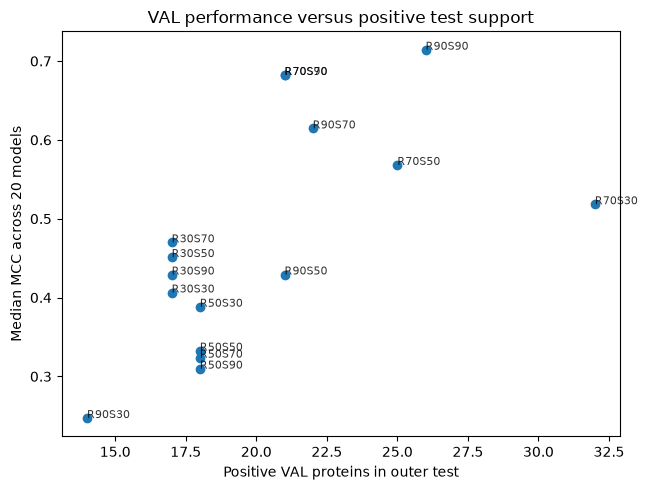

In [12]:
fig, ax = plt.subplots(figsize=(6.6, 5.0))
ax.scatter(
    cell_perf["n_positive_test"],
    cell_perf["mcc_median"],
)
for row in cell_perf.itertuples():
    ax.annotate(
        f"R{row.R}S{row.S}",
        (row.n_positive_test, row.mcc_median),
        fontsize=8,
        alpha=0.8,
    )
ax.set_xlabel("Positive VAL proteins in outer test")
ax.set_ylabel("Median MCC across 20 models")
ax.set_title("VAL performance versus positive test support")
plt.tight_layout()
plt.show()

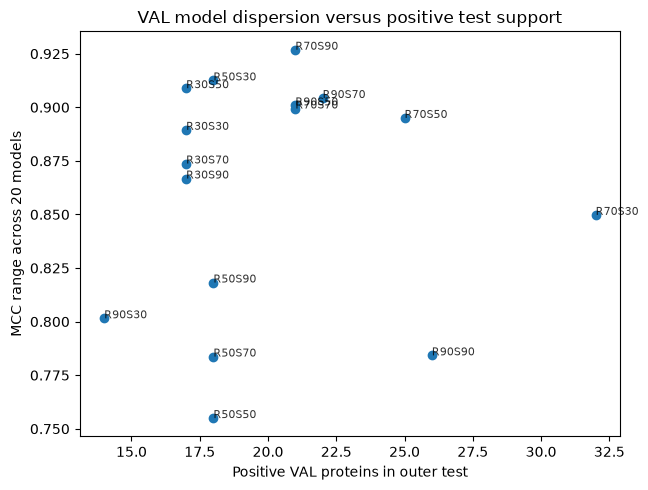

In [13]:
fig, ax = plt.subplots(figsize=(6.6, 5.0))
ax.scatter(
    cell_perf["n_positive_test"],
    cell_perf["mcc_range"],
)
for row in cell_perf.itertuples():
    ax.annotate(
        f"R{row.R}S{row.S}",
        (row.n_positive_test, row.mcc_range),
        fontsize=8,
        alpha=0.8,
    )
ax.set_xlabel("Positive VAL proteins in outer test")
ax.set_ylabel("MCC range across 20 models")
ax.set_title("VAL model dispersion versus positive test support")
plt.tight_layout()
plt.show()

# 8. Is volatility threshold-specific or also present in ranking metrics?

In [14]:
dispersion_cols = [
    c for c in [
        "mcc_iqr",
        "ap_iqr",
        "ap_skill_iqr",
        "roc_auc_iqr",
        "balanced_accuracy_iqr",
        "recall_iqr",
    ]
    if c in cell_perf.columns
]

display(
    cell_perf[
        ["R", "S", "n_positive_test", *dispersion_cols]
    ].sort_values("n_positive_test")
)

dispersion_assoc_rows = []

for c in dispersion_cols:
    x = cell_perf[["n_positive_test", c]].dropna()
    dispersion_assoc_rows.append(
        {
            "metric_dispersion": c,
            "n_cells": len(x),
            "spearman_positive_test_support": (
                x["n_positive_test"]
                .corr(x[c], method="spearman")
                if x["n_positive_test"].nunique() > 1
                else np.nan
            ),
        }
    )

dispersion_assoc = pd.DataFrame(dispersion_assoc_rows)
display(dispersion_assoc)

,R,S,n_positive_test,mcc_iqr,ap_iqr,ap_skill_iqr,roc_auc_iqr,balanced_accuracy_iqr,recall_iqr
12,90,30,14,0.361031,0.349019,0.349616,0.206017,0.195100,0.392857
0,30,30,17,0.564797,0.585287,0.589318,0.136896,0.271150,0.544118
2,30,70,17,0.561439,0.616330,0.620590,0.146760,0.244575,0.500000
1,30,50,17,0.530486,0.594837,0.598931,0.154209,0.249979,0.500000
3,30,90,17,0.512945,0.484941,0.488283,0.143280,0.249544,0.500000
4,50,30,18,0.678943,0.645099,0.647992,0.144020,0.291262,0.583333
6,50,70,18,0.562484,0.418423,0.420288,0.119722,0.207931,0.472222
5,50,50,18,0.605481,0.462192,0.464250,0.126625,0.215216,0.472222
7,50,90,18,0.622856,0.468233,0.470315,0.116553,0.256574,0.513889
11,70,90,21,0.381561,0.301343,0.302426,0.082567,0.185269,0.380952


,metric_dispersion,n_cells,spearman_positive_test_support
0,mcc_iqr,16,-0.068873
1,ap_iqr,16,-0.122774
2,ap_skill_iqr,16,-0.122774
3,roc_auc_iqr,16,-0.875890
4,balanced_accuracy_iqr,16,0.359339
5,recall_iqr,16,0.409049


If ranking metrics such as AP or ROC-AUC are also volatile at low support, the VAL problem cannot be reduced to the canonical 0.5 decision threshold alone.

# 9. Representation rescue under Low-N

In [15]:
def paired_rep_delta(df, rep_hi, rep_lo, metric="mcc"):
    rows = []

    for keys, grp in df.groupby(
        ["R", "S", "algorithm"]
    ):
        r, s, alg = keys
        lookup = dict(zip(grp["representation"], grp[metric]))

        if rep_hi in lookup and rep_lo in lookup:
            rows.append(
                {
                    "R": int(r),
                    "S": int(s),
                    "algorithm": alg,
                    "delta": lookup[rep_hi] - lookup[rep_lo],
                }
            )

    return pd.DataFrame(rows)

capacity = paired_rep_delta(
    val_models,
    T30,
    T6,
    "mcc",
)

t30_onehot = paired_rep_delta(
    val_models,
    T30,
    ONEHOT,
    "mcc",
)

capacity_cell = (
    capacity.groupby(["R", "S"])["delta"]
    .agg(
        T30_minus_T6_median="median",
        T30_minus_T6_mean="mean",
        T30_minus_T6_fraction_positive=lambda x: (x > 0).mean(),
    )
    .reset_index()
)

onehot_cell = (
    t30_onehot.groupby(["R", "S"])["delta"]
    .agg(
        T30_minus_onehot_median="median",
        T30_minus_onehot_mean="mean",
        T30_minus_onehot_fraction_positive=lambda x: (x > 0).mean(),
    )
    .reset_index()
)

representation_rescue = (
    val_support
    .merge(capacity_cell, on=["R", "S"], how="left")
    .merge(onehot_cell, on=["R", "S"], how="left")
)

display(representation_rescue)

,task,R,S,n_train,n_test,n_positive_train,n_positive_test,n_negative_train,n_negative_test,train_prevalence,test_prevalence,one_positive_recall_step,n_positive_train_clusters,n_positive_test_clusters,positive_test_entities_per_cluster,T30_minus_T6_median,T30_minus_T6_mean,T30_minus_T6_fraction_positive,T30_minus_onehot_median,T30_minus_onehot_mean,T30_minus_onehot_fraction_positive
0,subtype_val,90,90,19117,8192,63,26,19054,8166,0.003295,0.003174,0.038462,63,26,1.000000,0.054476,0.067570,0.8,0.537444,0.485418,1.0
1,subtype_val,90,70,19112,8197,67,22,19045,8175,0.003506,0.002684,0.045455,58,22,1.000000,0.110222,0.130467,1.0,0.641011,0.660939,1.0
2,subtype_val,90,50,19110,8199,68,21,19042,8178,0.003558,0.002561,0.047619,46,19,1.105263,0.118546,0.138913,1.0,0.568460,0.559436,1.0
3,subtype_val,90,30,19108,8201,75,14,19033,8187,0.003925,0.001707,0.071429,36,12,1.166667,0.485310,0.399627,1.0,0.706805,0.654838,1.0
4,subtype_val,70,90,13690,5865,59,21,13631,5844,0.004310,0.003581,0.047619,59,21,1.000000,0.080862,0.096129,1.0,0.392768,0.554118,1.0
5,subtype_val,70,70,13694,5861,59,21,13635,5840,0.004308,0.003583,0.047619,59,21,1.000000,0.128663,0.131059,1.0,0.495002,0.570838,1.0
6,subtype_val,70,50,13677,5878,55,25,13622,5853,0.004021,0.004253,0.040000,45,20,1.250000,0.165581,0.149967,1.0,0.825380,0.744218,1.0
7,subtype_val,70,30,13661,5894,48,32,13613,5862,0.003514,0.005429,0.031250,32,16,2.000000,0.237960,0.230069,1.0,0.847829,0.777661,1.0
8,subtype_val,50,90,9467,4066,46,18,9421,4048,0.004859,0.004427,0.055556,46,18,1.000000,0.227358,0.262340,1.0,0.781061,0.726676,1.0
9,subtype_val,50,70,9477,4056,46,18,9431,4038,0.004854,0.004438,0.055556,46,18,1.000000,0.188657,0.206273,1.0,0.691750,0.626097,1.0


In [16]:
rescue_assoc = []

for gain_col in [
    "T30_minus_T6_median",
    "T30_minus_onehot_median",
]:
    for support_col in [
        "n_positive_train",
        "n_positive_test",
    ]:
        x = representation_rescue[
            [support_col, gain_col]
        ].dropna()

        rescue_assoc.append(
            {
                "gain": gain_col,
                "support": support_col,
                "n_cells": len(x),
                "spearman_rho": (
                    x[support_col]
                    .corr(
                        x[gain_col],
                        method="spearman",
                    )
                    if x[support_col].nunique() > 1
                    else np.nan
                ),
            }
        )

display(pd.DataFrame(rescue_assoc))

,gain,support,n_cells,spearman_rho
0,T30_minus_T6_median,n_positive_train,16,0.14789
1,T30_minus_T6_median,n_positive_test,16,-0.05989
2,T30_minus_onehot_median,n_positive_train,16,-0.52583
3,T30_minus_onehot_median,n_positive_test,16,-0.22309


A larger T30 gain when support is lower would be compatible with stronger representations partially compensating for sparse supervised evidence. It would **not** imply that PLMs eliminate the Low-N problem.

# 10. Classifier dependence under Low-N

In [17]:
algorithm_spread_rows = []

for keys, grp in val_models.groupby(
    ["R", "S", "representation"]
):
    r, s, rep = keys
    vals = grp["mcc"].dropna()

    algorithm_spread_rows.append(
        {
            "R": int(r),
            "S": int(s),
            "representation": rep,
            "algorithm_range": vals.max() - vals.min(),
            "algorithm_iqr": vals.quantile(0.75) - vals.quantile(0.25),
        }
    )

algorithm_spread = pd.DataFrame(
    algorithm_spread_rows
)

algorithm_spread_cell = (
    algorithm_spread.groupby(["R", "S"])
    .agg(
        median_algorithm_range=("algorithm_range", "median"),
        median_algorithm_iqr=("algorithm_iqr", "median"),
    )
    .reset_index()
    .merge(
        val_support,
        on=["R", "S"],
        how="left",
    )
)

display(algorithm_spread_cell)

for support_col in ["n_positive_train", "n_positive_test"]:
    rho = (
        algorithm_spread_cell[support_col]
        .corr(
            algorithm_spread_cell["median_algorithm_range"],
            method="spearman",
        )
    )
    print(
        f"Spearman {support_col} vs algorithm range:",
        rho,
    )

,R,S,median_algorithm_range,median_algorithm_iqr,task,n_train,n_test,n_positive_train,n_positive_test,n_negative_train,n_negative_test,train_prevalence,test_prevalence,one_positive_recall_step,n_positive_train_clusters,n_positive_test_clusters,positive_test_entities_per_cluster
0,30,30,0.279115,0.084801,subtype_val,5795,2485,31,17,5764,2468,0.005349,0.006841,0.058824,31,17,1.000000
1,30,50,0.369931,0.168761,subtype_val,5793,2487,31,17,5762,2470,0.005351,0.006836,0.058824,31,17,1.000000
2,30,70,0.328034,0.175553,subtype_val,5803,2477,31,17,5772,2460,0.005342,0.006863,0.058824,31,17,1.000000
3,30,90,0.276280,0.154659,subtype_val,5796,2484,31,17,5765,2467,0.005349,0.006844,0.058824,31,17,1.000000
4,50,30,0.380359,0.103065,subtype_val,9501,4032,46,18,9455,4014,0.004842,0.004464,0.055556,34,14,1.285714
5,50,50,0.308540,0.087001,subtype_val,9473,4060,46,18,9427,4042,0.004856,0.004433,0.055556,46,18,1.000000
6,50,70,0.279549,0.053426,subtype_val,9477,4056,46,18,9431,4038,0.004854,0.004438,0.055556,46,18,1.000000
7,50,90,0.302342,0.073091,subtype_val,9467,4066,46,18,9421,4048,0.004859,0.004427,0.055556,46,18,1.000000
8,70,30,0.294034,0.162994,subtype_val,13661,5894,48,32,13613,5862,0.003514,0.005429,0.031250,32,16,2.000000
9,70,50,0.345124,0.100104,subtype_val,13677,5878,55,25,13622,5853,0.004021,0.004253,0.040000,45,20,1.250000


Spearman n_positive_train vs algorithm range: 0.21660617762828394
Spearman n_positive_test vs algorithm range: 0.18116695891203427


# 11. Load per-sequence VAL outer-test predictions

In [18]:
def val_experiment_dir(r, s, representation, algorithm):
    return (
        TRAINING_ROOT
        / TASK_PATHS[VAL_TASK]
        / f"R{r}_S{s}"
        / representation
        / algorithm
    )

prediction_frames = []
missing_prediction_files = []

for r in R_LEVELS:
    for s in S_LEVELS:
        for rep in REPS:
            for alg in ALGORITHMS:
                path = (
                    val_experiment_dir(r, s, rep, alg)
                    / "outer_test_predictions.parquet"
                )

                if not path.is_file():
                    missing_prediction_files.append(str(path))
                    continue

                pred = pd.read_parquet(
                    path,
                    columns=[
                        "entity_id",
                        "sequence_uid",
                        "y_true",
                        "y_pred",
                        "score_positive",
                    ],
                )

                pred["R"] = r
                pred["S"] = s
                pred["representation"] = rep
                pred["algorithm"] = alg

                prediction_frames.append(pred)

if missing_prediction_files:
    raise FileNotFoundError(
        f"Missing {len(missing_prediction_files)} prediction files. "
        f"First: {missing_prediction_files[0]}"
    )

val_predictions = pd.concat(
    prediction_frames,
    ignore_index=True,
)

print("Loaded prediction rows:", len(val_predictions))
print(
    "Unique model families:",
    val_predictions[
        ["R", "S", "representation", "algorithm"]
    ].drop_duplicates().shape[0],
)

Loaded prediction rows: 1648680
Unique model families: 320


# 12. Validate prediction-derived positive support

In [19]:
pred_support = (
    val_predictions.assign(
        is_positive=lambda x: pd.to_numeric(
            x["y_true"],
            errors="coerce",
        ).eq(1)
    )
    .groupby(["R", "S"])
    .agg(
        n_models=(
            "representation",
            lambda x: len(x) // x.groupby(level=0).size().iloc[0]
            if False else np.nan
        ),
        total_positive_prediction_rows=(
            "is_positive",
            "sum",
        ),
    )
    .reset_index()
)

# More transparent support validation:
support_checks = []

for (r, s), grp in val_predictions.groupby(["R", "S"]):
    n_models = (
        grp[["representation", "algorithm"]]
        .drop_duplicates()
        .shape[0]
    )

    per_model = (
        grp.assign(
            is_positive=pd.to_numeric(
                grp["y_true"],
                errors="coerce",
            ).eq(1)
        )
        .groupby(["representation", "algorithm"])["is_positive"]
        .sum()
    )

    support_checks.append(
        {
            "R": int(r),
            "S": int(s),
            "n_models": n_models,
            "unique_positive_support_counts": per_model.nunique(),
            "prediction_positive_support": int(per_model.iloc[0]),
        }
    )

prediction_support_check = (
    pd.DataFrame(support_checks)
    .merge(
        val_support[
            ["R", "S", "n_positive_test"]
        ],
        on=["R", "S"],
        how="left",
    )
)

prediction_support_check["matches_eligible_support"] = (
    prediction_support_check["prediction_positive_support"]
    == prediction_support_check["n_positive_test"]
)

display(prediction_support_check)

assert prediction_support_check[
    "unique_positive_support_counts"
].eq(1).all()

assert prediction_support_check[
    "matches_eligible_support"
].all()

,R,S,n_models,unique_positive_support_counts,prediction_positive_support,n_positive_test,matches_eligible_support
0,30,30,20,1,17,17,True
1,30,50,20,1,17,17,True
2,30,70,20,1,17,17,True
3,30,90,20,1,17,17,True
4,50,30,20,1,18,18,True
5,50,50,20,1,18,18,True
6,50,70,20,1,18,18,True
7,50,90,20,1,18,18,True
8,70,30,20,1,32,32,True
9,70,50,20,1,25,25,True


# 13. Model agreement on the scarce positive VAL proteins

In [20]:
positive_predictions = val_predictions[
    pd.to_numeric(
        val_predictions["y_true"],
        errors="coerce",
    ).eq(1)
].copy()

positive_predictions["correct_positive"] = (
    pd.to_numeric(
        positive_predictions["y_pred"],
        errors="coerce",
    ).eq(1)
)

positive_agreement = (
    positive_predictions.groupby(
        ["R", "S", "entity_id", "sequence_uid"]
    )
    .agg(
        n_models=("correct_positive", "size"),
        fraction_models_predict_positive=(
            "correct_positive",
            "mean",
        ),
        median_score_positive=("score_positive", "median"),
        score_iqr=(
            "score_positive",
            lambda x: x.quantile(0.75) - x.quantile(0.25),
        ),
    )
    .reset_index()
)

def vote_entropy(p):
    if pd.isna(p) or p <= 0 or p >= 1:
        return 0.0
    return float(
        -p * math.log2(p)
        - (1 - p) * math.log2(1 - p)
    )

positive_agreement["vote_entropy_bits"] = (
    positive_agreement[
        "fraction_models_predict_positive"
    ].map(vote_entropy)
)

def agreement_class(p):
    if p >= 0.8:
        return "stable_recognition"
    if p <= 0.2:
        return "stable_miss"
    return "model_dependent"

positive_agreement["agreement_class"] = (
    positive_agreement[
        "fraction_models_predict_positive"
    ].map(agreement_class)
)

display(positive_agreement.head())

,R,S,entity_id,sequence_uid,n_models,fraction_models_predict_positive,median_score_positive,score_iqr,vote_entropy_bits,agreement_class
0,30,30,PLDSEQ_0b611807485a43853ffd59e6cad3661be441c5a...,0b611807485a43853ffd59e6cad3661be441c5ac1d29c9...,20,0.25,0.314626,0.529772,0.811278,model_dependent
1,30,30,PLDSEQ_1573d4a7c87c673a976fe46dc63e40f74a71afd...,1573d4a7c87c673a976fe46dc63e40f74a71afdfc028c3...,20,0.05,0.000123,0.082124,0.286397,stable_miss
2,30,30,PLDSEQ_337b78c1730e387bec4be3771862d12bb5032a3...,337b78c1730e387bec4be3771862d12bb5032a389ebb61...,20,0.60,0.872575,0.847365,0.970951,model_dependent
3,30,30,PLDSEQ_33c4d17580bce89f4f231891520a533e8e91d83...,33c4d17580bce89f4f231891520a533e8e91d83475e7ff...,20,0.30,0.119975,0.616241,0.881291,model_dependent
4,30,30,PLDSEQ_5ae781270df2efb9af53e23d5ee6e8dab7cc581...,5ae781270df2efb9af53e23d5ee6e8dab7cc5810e51a9b...,20,0.70,0.894133,0.659177,0.881291,model_dependent


# 14. Positive-protein agreement by R×S cell

In [21]:
agreement_cell = (
    positive_agreement.groupby(["R", "S"])
    .agg(
        n_positive_entities=("sequence_uid", "size"),
        median_model_vote=(
            "fraction_models_predict_positive",
            "median",
        ),
        mean_model_vote=(
            "fraction_models_predict_positive",
            "mean",
        ),
        mean_vote_entropy=(
            "vote_entropy_bits",
            "mean",
        ),
        median_score_iqr=("score_iqr", "median"),
        fraction_stable_recognition=(
            "agreement_class",
            lambda x: (x == "stable_recognition").mean(),
        ),
        fraction_model_dependent=(
            "agreement_class",
            lambda x: (x == "model_dependent").mean(),
        ),
        fraction_stable_miss=(
            "agreement_class",
            lambda x: (x == "stable_miss").mean(),
        ),
    )
    .reset_index()
    .merge(
        val_support,
        on=["R", "S"],
        how="left",
    )
)

display(agreement_cell)

,R,S,n_positive_entities,median_model_vote,mean_model_vote,mean_vote_entropy,median_score_iqr,fraction_stable_recognition,fraction_model_dependent,fraction_stable_miss,task,n_train,n_test,n_positive_train,n_positive_test,n_negative_train,n_negative_test,train_prevalence,test_prevalence,one_positive_recall_step,n_positive_train_clusters,n_positive_test_clusters,positive_test_entities_per_cluster
0,30,30,17,0.300,0.350000,0.798297,0.623533,0.000000,0.647059,0.352941,subtype_val,5795,2485,31,17,5764,2468,0.005349,0.006841,0.058824,31,17,1.000000
1,30,50,17,0.250,0.317647,0.736973,0.592384,0.000000,0.588235,0.411765,subtype_val,5793,2487,31,17,5762,2470,0.005351,0.006836,0.058824,31,17,1.000000
2,30,70,17,0.350,0.344118,0.790562,0.651365,0.000000,0.647059,0.352941,subtype_val,5803,2477,31,17,5772,2460,0.005342,0.006863,0.058824,31,17,1.000000
3,30,90,17,0.300,0.335294,0.779097,0.622407,0.000000,0.588235,0.411765,subtype_val,5796,2484,31,17,5765,2467,0.005349,0.006844,0.058824,31,17,1.000000
4,50,30,18,0.350,0.336111,0.838019,0.621156,0.000000,0.722222,0.277778,subtype_val,9501,4032,46,18,9455,4014,0.004842,0.004464,0.055556,34,14,1.285714
5,50,50,18,0.350,0.300000,0.657464,0.664384,0.000000,0.611111,0.388889,subtype_val,9473,4060,46,18,9427,4042,0.004856,0.004433,0.055556,46,18,1.000000
6,50,70,18,0.350,0.291667,0.647258,0.655892,0.000000,0.611111,0.388889,subtype_val,9477,4056,46,18,9431,4038,0.004854,0.004438,0.055556,46,18,1.000000
7,50,90,18,0.300,0.288889,0.635246,0.663792,0.000000,0.611111,0.388889,subtype_val,9467,4066,46,18,9421,4048,0.004859,0.004427,0.055556,46,18,1.000000
8,70,30,32,0.450,0.382812,0.768082,0.830920,0.000000,0.750000,0.250000,subtype_val,13661,5894,48,32,13613,5862,0.003514,0.005429,0.031250,32,16,2.000000
9,70,50,25,0.450,0.416000,0.785555,0.594207,0.000000,0.760000,0.240000,subtype_val,13677,5878,55,25,13622,5853,0.004021,0.004253,0.040000,45,20,1.250000


In [22]:
agreement_assoc_rows = []

for outcome in [
    "mean_model_vote",
    "mean_vote_entropy",
    "fraction_model_dependent",
    "fraction_stable_miss",
]:
    for support_col in [
        "n_positive_train",
        "n_positive_test",
    ]:
        x = agreement_cell[
            [support_col, outcome]
        ].dropna()

        agreement_assoc_rows.append(
            {
                "support": support_col,
                "outcome": outcome,
                "n_cells": len(x),
                "spearman_rho": (
                    x[support_col]
                    .corr(
                        x[outcome],
                        method="spearman",
                    )
                    if x[support_col].nunique() > 1
                    else np.nan
                ),
            }
        )

agreement_associations = pd.DataFrame(
    agreement_assoc_rows
)

display(agreement_associations)

,support,outcome,n_cells,spearman_rho
0,n_positive_train,mean_model_vote,16,0.386903
1,n_positive_test,mean_model_vote,16,0.694723
2,n_positive_train,mean_vote_entropy,16,-0.204655
3,n_positive_test,mean_vote_entropy,16,0.067376
4,n_positive_train,fraction_model_dependent,16,0.207065
5,n_positive_test,fraction_model_dependent,16,0.672242
6,n_positive_train,fraction_stable_miss,16,-0.453142
7,n_positive_test,fraction_stable_miss,16,-0.816616


This separates two phenomena:

- **metric fragility** caused by evaluating only a few positives;
- **prediction fragility** where the identity of correctly recognized VAL proteins changes substantially across representations/learners.

Low test support can amplify the first even if individual predictions are stable. High model disagreement indicates that the second is also present.

# 15. Are some VAL proteins recurrently easy or difficult?

In [23]:
sequence_stability = (
    positive_agreement.groupby(
        ["entity_id", "sequence_uid"]
    )
    .agg(
        n_test_cell_exposures=("R", "size"),
        mean_fraction_models_predict_positive=(
            "fraction_models_predict_positive",
            "mean",
        ),
        min_fraction_models_predict_positive=(
            "fraction_models_predict_positive",
            "min",
        ),
        max_fraction_models_predict_positive=(
            "fraction_models_predict_positive",
            "max",
        ),
        mean_vote_entropy=("vote_entropy_bits", "mean"),
        median_score_positive=("median_score_positive", "median"),
    )
    .reset_index()
)

sequence_stability["recognition_range"] = (
    sequence_stability["max_fraction_models_predict_positive"]
    - sequence_stability["min_fraction_models_predict_positive"]
)

display(
    sequence_stability.sort_values(
        [
            "n_test_cell_exposures",
            "mean_fraction_models_predict_positive",
        ],
        ascending=[False, True],
    ).head(30)
)

,entity_id,sequence_uid,n_test_cell_exposures,mean_fraction_models_predict_positive,min_fraction_models_predict_positive,max_fraction_models_predict_positive,mean_vote_entropy,median_score_positive,recognition_range
41,PLDSEQ_8019a356608172c66c47e76652271a7319a1a55...,8019a356608172c66c47e76652271a7319a1a55344e05f...,10,0.425000,0.30,0.45,0.977261,0.310164,0.15
45,PLDSEQ_85e8529c1c11a304af9e1b5ad7a13343518dde0...,85e8529c1c11a304af9e1b5ad7a13343518dde023979fc...,10,0.675000,0.60,0.70,0.906090,0.888528,0.10
47,PLDSEQ_869b92b3e24aa7044e39ff78cfd15081f8611b8...,869b92b3e24aa7044e39ff78cfd15081f8611b8d2ea85b...,9,0.183333,0.05,0.30,0.645541,0.022070,0.25
60,PLDSEQ_b3150894f28ff3a104883ff25486a05a3bf8a7e...,b3150894f28ff3a104883ff25486a05a3bf8a7ee017351...,8,0.012500,0.00,0.05,0.071599,0.000342,0.05
69,PLDSEQ_d8786a6b133a5ae9088bbf88f6dfaec612effd0...,d8786a6b133a5ae9088bbf88f6dfaec612effd03c64f0a...,8,0.125000,0.10,0.15,0.539418,0.000353,0.05
1,PLDSEQ_0bccd45baba063468f06d221a73411802459ff9...,0bccd45baba063468f06d221a73411802459ff9739531c...,8,0.475000,0.45,0.50,0.996387,0.444579,0.05
36,PLDSEQ_75783e772d81b099635566f553f559571169116...,75783e772d81b099635566f553f559571169116663059f...,7,0.135714,0.05,0.20,0.559526,0.006447,0.15
43,PLDSEQ_83cf73c42a0ea33a81f9cb4d553a7934d82f90a...,83cf73c42a0ea33a81f9cb4d553a7934d82f90aaa2baeb...,7,0.135714,0.10,0.15,0.569599,0.015599,0.05
61,PLDSEQ_bb94d503654c8d21e3467a178f6597d5d78b6f0...,bb94d503654c8d21e3467a178f6597d5d78b6f09d1ca8b...,7,0.257143,0.15,0.30,0.812507,0.105803,0.15
74,PLDSEQ_ea05a21a4facc99819ab020248d46a40b68a056...,ea05a21a4facc99819ab020248d46a40b68a0565d0c2e9...,7,0.385714,0.35,0.45,0.958261,0.136786,0.10


In [24]:
print("VAL positive sequences recurrently exposed in >=2 test cells:")
display(
    sequence_stability[
        sequence_stability["n_test_cell_exposures"] >= 2
    ][
        [
            "n_test_cell_exposures",
            "mean_fraction_models_predict_positive",
            "recognition_range",
            "mean_vote_entropy",
        ]
    ].describe()
)

VAL positive sequences recurrently exposed in >=2 test cells:


,n_test_cell_exposures,mean_fraction_models_predict_positive,recognition_range,mean_vote_entropy
count,69.000000,69.000000,69.000000,69.000000
mean,4.507246,0.404217,0.147826,0.753062
std,2.083713,0.240882,0.127312,0.262566
min,2.000000,0.010000,0.000000,0.057279
25%,3.000000,0.183333,0.050000,0.635006
50%,4.000000,0.433333,0.100000,0.860654
75%,6.000000,0.625000,0.250000,0.946728
max,10.000000,0.800000,0.600000,1.000000


Repeated exposure of the same sequence across different native R/S test sets is descriptive only. Training sets differ across regimes, so changes in recognition cannot be attributed to the sequence alone.

# 16. Context: positive support across all subtype tasks

In [25]:
def subtype_support_table(task):
    rows = []

    for r in R_LEVELS:
        for s in S_LEVELS:
            path = resolve_eligible_path(task, r, s)
            df = pd.read_csv(path, sep="\t", low_memory=False)

            if "label" not in df.columns:
                raise KeyError(
                    f"{path}: missing label column. Available columns: {list(df.columns)}"
                )

            split_col = infer_split_column(df)
            cluster_col = infer_cluster_column(df)

            split = normalize_split(df[split_col])
            pos = binary_positive_mask(df["label"])

            row = {
                "task": task,
                "R": r,
                "S": s,
                "n_positive_train": int(
                    (split.eq("train") & pos).sum()
                ),
                "n_positive_test": int(
                    (split.eq("test") & pos).sum()
                ),
            }

            if cluster_col is not None:
                row["n_positive_train_clusters"] = int(
                    df.loc[
                        split.eq("train") & pos,
                        cluster_col,
                    ].nunique()
                )
                row["n_positive_test_clusters"] = int(
                    df.loc[
                        split.eq("test") & pos,
                        cluster_col,
                    ].nunique()
                )

            rows.append(row)

    return pd.DataFrame(rows)

subtype_support = pd.concat(
    [
        subtype_support_table(task)
        for task in SUBTYPE_TASKS
    ],
    ignore_index=True,
)

display(
    subtype_support.groupby("task")
    .agg(
        min_positive_train=("n_positive_train", "min"),
        median_positive_train=("n_positive_train", "median"),
        max_positive_train=("n_positive_train", "max"),
        min_positive_test=("n_positive_test", "min"),
        median_positive_test=("n_positive_test", "median"),
        max_positive_test=("n_positive_test", "max"),
    )
)

,min_positive_train,median_positive_train,max_positive_train,min_positive_test,median_positive_test,max_positive_test
task,,,,,,
subtype_depolymerase,230,276.5,334,87,116.5,144
subtype_endolysin,836,1667.5,2799,362,680.0,1340
subtype_val,31,47.0,75,14,18.0,32


# 17. Context: does subtype model dispersion track positive support?

In [26]:
subtype_model_rows = []

for task in SUBTYPE_TASKS:
    task_master = master[
        master["task"].eq(task)
    ]

    task_support = subtype_support[
        subtype_support["task"].eq(task)
    ]

    cell = (
        task_master.groupby(["R", "S"])
        .agg(
            mcc_median=("mcc", "median"),
            mcc_range=("mcc", lambda x: x.max() - x.min()),
            mcc_iqr=("mcc", lambda x: x.quantile(0.75) - x.quantile(0.25)),
        )
        .reset_index()
        .merge(
            task_support,
            on=["R", "S"],
            how="left",
        )
    )

    subtype_model_rows.append(cell)

subtype_context = pd.concat(
    subtype_model_rows,
    ignore_index=True,
)

display(
    subtype_context.groupby("task")
    .agg(
        median_positive_test=("n_positive_test", "median"),
        median_mcc=("mcc_median", "median"),
        median_mcc_range=("mcc_range", "median"),
        median_mcc_iqr=("mcc_iqr", "median"),
    )
)

,median_positive_test,median_mcc,median_mcc_range,median_mcc_iqr
task,,,,
subtype_depolymerase,116.5,0.840519,0.918235,0.161519
subtype_endolysin,680.0,0.663245,0.816977,0.361980
subtype_val,18.0,0.440300,0.881620,0.521769


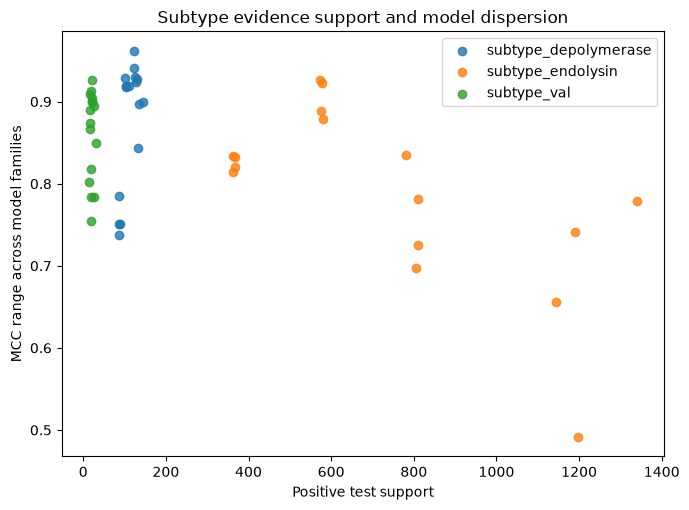

In [27]:
fig, ax = plt.subplots(figsize=(7, 5.2))

for task, grp in subtype_context.groupby("task"):
    ax.scatter(
        grp["n_positive_test"],
        grp["mcc_range"],
        label=task,
        alpha=0.8,
    )

ax.set_xlabel("Positive test support")
ax.set_ylabel("MCC range across model families")
ax.set_title("Subtype evidence support and model dispersion")
ax.legend()
plt.tight_layout()
plt.show()

This contextual analysis is not a controlled experiment because subtype biology differs. Its role is to show whether VAL occupies an extreme support regime relative to the other subtype tasks.

# 18. VAL support inside the clean multiclass task

In [28]:
multi_support_rows = []

for r in R_LEVELS:
    for s in S_LEVELS:
        path = resolve_eligible_path(MULTI_TASK, r, s)
        df = pd.read_csv(path, sep="\t", low_memory=False)

        split_col = infer_split_column(df)
        cluster_col = infer_cluster_column(df)

        split = normalize_split(df[split_col])
        val_mask, val_class_source = val_class_mask(df)

        row = {
            "task": MULTI_TASK,
            "R": r,
            "S": s,
            "n_train": int(split.eq("train").sum()),
            "n_test": int(split.eq("test").sum()),
            "n_val_train": int(
                (split.eq("train") & val_mask).sum()
            ),
            "n_val_test": int(
                (split.eq("test") & val_mask).sum()
            ),
            "val_class_source": val_class_source,
        }

        row["one_val_recall_step"] = (
            1.0 / row["n_val_test"]
            if row["n_val_test"] else np.nan
        )

        if cluster_col is not None:
            row["n_val_train_clusters"] = int(
                df.loc[
                    split.eq("train") & val_mask,
                    cluster_col,
                ].nunique()
            )
            row["n_val_test_clusters"] = int(
                df.loc[
                    split.eq("test") & val_mask,
                    cluster_col,
                ].nunique()
            )

        multi_support_rows.append(row)

multiclass_val_support = pd.DataFrame(
    multi_support_rows
)

display(multiclass_val_support)

print("Multiclass VAL test support matrix")
display(
    multiclass_val_support.pivot(
        index="R",
        columns="S",
        values="n_val_test",
    ).reindex(index=R_LEVELS, columns=S_LEVELS)
)

,task,R,S,n_train,n_test,n_val_train,n_val_test,val_class_source,one_val_recall_step,n_val_train_clusters,n_val_test_clusters
0,multiclass_clean,90,90,3150,1342,55,34,class_name,0.029412,55,34
1,multiclass_clean,90,70,3141,1351,53,36,class_name,0.027778,50,30
2,multiclass_clean,90,50,3127,1365,65,24,class_name,0.041667,47,17
3,multiclass_clean,90,30,3178,1314,62,27,class_name,0.037037,34,14
4,multiclass_clean,70,90,2321,997,58,22,class_name,0.045455,58,22
5,multiclass_clean,70,70,2335,983,62,18,class_name,0.055556,61,18
6,multiclass_clean,70,50,2330,988,55,25,class_name,0.040000,46,17
7,multiclass_clean,70,30,2311,1007,50,30,class_name,0.033333,34,14
8,multiclass_clean,50,90,1632,699,40,24,class_name,0.041667,40,24
9,multiclass_clean,50,70,1629,702,46,18,class_name,0.055556,46,18


Multiclass VAL test support matrix


S,90,70,50,30
R,,,,
90,34,36,24,27
70,22,18,25,30
50,24,18,22,22
30,16,16,15,14


# 19. Multiclass per-class VAL performance, when available

In [29]:
per_class_path = STAGE12A / "per_class_results.tsv"

multi_val_per_class = pd.DataFrame()

if per_class_path.is_file():
    per_class = pd.read_csv(
        per_class_path,
        sep="\t",
        low_memory=False,
    )

    pc = per_class[
        per_class["task"].eq(MULTI_TASK)
    ].copy()

    class_col = next(
        (
            c for c in [
                "class_name",
                "class",
                "label",
                "target_class",
            ]
            if c in pc.columns
        ),
        None,
    )

    if class_col is not None:
        class_text = (
            pc[class_col]
            .astype(str)
            .str.lower()
            .str.replace("-", "_", regex=False)
            .str.replace(" ", "_", regex=False)
        )

        val_pc_mask = (
            class_text.str.contains("virion", na=False)
            | class_text.eq("val")
        )

        multi_val_per_class = pc[
            val_pc_mask
        ].copy()

        if len(multi_val_per_class):
            multi_val_per_class = (
                multi_val_per_class.merge(
                    multiclass_val_support,
                    on=["R", "S"],
                    how="left",
                    validate="many_to_one",
                )
            )

            metric_cols = [
                c for c in [
                    "precision",
                    "recall",
                    "f1",
                    "f1_score",
                    "support",
                ]
                if c in multi_val_per_class.columns
            ]

            print(
                "Multiclass VAL per-class metrics:",
                metric_cols,
            )

            if metric_cols:
                agg = {
                    f"{c}_median": (c, "median")
                    for c in metric_cols
                }

                multi_val_cell = (
                    multi_val_per_class.groupby(
                        ["R", "S"]
                    )
                    .agg(**agg)
                    .reset_index()
                    .merge(
                        multiclass_val_support,
                        on=["R", "S"],
                        how="left",
                    )
                )

                display(multi_val_cell)
        else:
            print(
                "No VAL per-class rows detected in per_class_results.tsv."
            )
    else:
        print(
            "No class identifier column detected in per_class_results.tsv."
        )
else:
    print("No per_class_results.tsv found.")

Multiclass VAL per-class metrics: ['precision', 'recall', 'f1', 'support']


,R,S,precision_median,recall_median,f1_median,support_median,task,n_train,n_test,n_val_train,n_val_test,val_class_source,one_val_recall_step,n_val_train_clusters,n_val_test_clusters
0,30,30,0.387500,0.142857,0.230323,14.0,multiclass_clean,1099,472,34,14,class_name,0.071429,34,14
1,30,50,0.436508,0.233333,0.284512,15.0,multiclass_clean,1099,472,33,15,class_name,0.066667,33,15
2,30,70,0.472222,0.250000,0.285000,16.0,multiclass_clean,1096,475,32,16,class_name,0.062500,32,16
3,30,90,0.472222,0.250000,0.285000,16.0,multiclass_clean,1096,475,32,16,class_name,0.062500,32,16
4,50,30,0.387500,0.159091,0.187379,22.0,multiclass_clean,1650,681,42,22,class_name,0.045455,29,19
5,50,50,0.516667,0.318182,0.359914,22.0,multiclass_clean,1632,699,42,22,class_name,0.045455,42,22
6,50,70,0.380952,0.222222,0.253333,18.0,multiclass_clean,1629,702,46,18,class_name,0.055556,46,18
7,50,90,0.666667,0.208333,0.317540,24.0,multiclass_clean,1632,699,40,24,class_name,0.041667,40,24
8,70,30,0.439407,0.250000,0.294770,30.0,multiclass_clean,2311,1007,50,30,class_name,0.033333,34,14
9,70,50,0.442222,0.340000,0.322857,25.0,multiclass_clean,2330,988,55,25,class_name,0.040000,46,17


The multiclass analysis asks a narrower question than overall multiclass MCC: **how well is the minority VAL class itself resolved?** A strong global multiclass metric can coexist with uncertain VAL-class recall/F1 when the class has only a few test proteins.

# 20. Binary VAL metric granularity using TP/FN, when available

In [30]:
count_cols = [
    c for c in ["tp", "fn", "tn", "fp"]
    if c in val_models.columns
]

if {"tp", "fn"} <= set(val_models.columns):
    val_models["positive_count_from_confusion"] = (
        pd.to_numeric(
            val_models["tp"],
            errors="coerce",
        )
        + pd.to_numeric(
            val_models["fn"],
            errors="coerce",
        )
    )

    val_models["support_match_confusion"] = (
        val_models["positive_count_from_confusion"]
        == val_models["n_positive_test"]
    )

    print(
        "Confusion-derived support matches frozen eligible support:",
        val_models["support_match_confusion"].mean(),
    )

    val_models["recall_from_counts"] = (
        pd.to_numeric(
            val_models["tp"],
            errors="coerce",
        )
        / val_models["n_positive_test"]
    )

    display(
        val_models[
            [
                "R",
                "S",
                "representation",
                "algorithm",
                "n_positive_test",
                "tp",
                "fn",
                "recall_from_counts",
            ]
        ]
        .sort_values(
            ["n_positive_test", "R", "S"]
        )
        .head(30)
    )
else:
    print(
        "TP/FN columns are not present in the Stage12A master table; "
        "per-sequence predictions already provide the required support audit."
    )

Confusion-derived support matches frozen eligible support: 1.0


,R,S,representation,algorithm,n_positive_test,tp,fn,recall_from_counts
60,90,30,roxy_48,LR,14,9.0,5.0,0.642857
61,90,30,roxy_48,RF,14,0.0,14.0,0.000000
62,90,30,roxy_48,KNN,14,2.0,12.0,0.142857
63,90,30,roxy_48,XGB,14,4.0,10.0,0.285714
64,90,30,roxy_48,MLP,14,3.0,11.0,0.214286
65,90,30,onehot_1024,LR,14,0.0,14.0,0.000000
66,90,30,onehot_1024,RF,14,0.0,14.0,0.000000
67,90,30,onehot_1024,KNN,14,0.0,14.0,0.000000
68,90,30,onehot_1024,XGB,14,0.0,14.0,0.000000
69,90,30,onehot_1024,MLP,14,0.0,14.0,0.000000


# 21. What conclusions remain stable when VAL support is exposed?

In [31]:
evidence_rows = []

evidence_rows.append(
    {
        "evidence": "binary_VAL_positive_support",
        "value": (
            f"train {val_support['n_positive_train'].min()}–"
            f"{val_support['n_positive_train'].max()}; "
            f"test {val_support['n_positive_test'].min()}–"
            f"{val_support['n_positive_test'].max()}"
        ),
    }
)

evidence_rows.append(
    {
        "evidence": "one_positive_recall_resolution",
        "value": (
            f"{100*val_support['one_positive_recall_step'].min():.2f}%–"
            f"{100*val_support['one_positive_recall_step'].max():.2f}%"
        ),
    }
)

evidence_rows.append(
    {
        "evidence": "median_VAL_MCC",
        "value": float(val_models["mcc"].median()),
    }
)

evidence_rows.append(
    {
        "evidence": "median_cell_MCC_range",
        "value": float(cell_perf["mcc_range"].median()),
    }
)

evidence_rows.append(
    {
        "evidence": "median_T30_minus_T6",
        "value": float(capacity["delta"].median()),
    }
)

evidence_rows.append(
    {
        "evidence": "median_T30_minus_onehot",
        "value": float(t30_onehot["delta"].median()),
    }
)

evidence_rows.append(
    {
        "evidence": "median_positive_model_vote",
        "value": float(
            positive_agreement[
                "fraction_models_predict_positive"
            ].median()
        ),
    }
)

evidence_rows.append(
    {
        "evidence": "fraction_positive_exposures_model_dependent",
        "value": float(
            (
                positive_agreement[
                    "agreement_class"
                ] == "model_dependent"
            ).mean()
        ),
    }
)

evidence_rows.append(
    {
        "evidence": "multiclass_VAL_test_support",
        "value": (
            f"{multiclass_val_support['n_val_test'].min()}–"
            f"{multiclass_val_support['n_val_test'].max()}"
        ),
    }
)

rq10_evidence_summary = pd.DataFrame(
    evidence_rows
)

display(rq10_evidence_summary)

,evidence,value
0,binary_VAL_positive_support,train 31–75; test 14–32
1,one_positive_recall_resolution,3.12%–7.14%
2,median_VAL_MCC,0.483795
3,median_cell_MCC_range,0.88162
4,median_T30_minus_T6,0.121127
5,median_T30_minus_onehot,0.685345
6,median_positive_model_vote,0.4
7,fraction_positive_exposures_model_dependent,0.652174
8,multiclass_VAL_test_support,14–36


# 22. RQ10 synthesis questions

After execution, RQ10 should answer:

1. What are the exact VAL positive train/test counts in each R×S cell?
2. How many positive homology components support those counts?
3. How coarse is recall resolution when a single positive protein changes the metric?
4. Does R reduce the amount of learnable VAL evidence?
5. Does S materially redistribute scarce positive support between train and test?
6. Are lower-support cells associated with lower median performance?
7. Are lower-support cells associated with greater model-to-model dispersion?
8. Is instability visible in AP/AUC as well as MCC?
9. Does ESM2-T30 retain a substantial advantage over T6 and one-hot in Low-N VAL?
10. Does classifier dependence become larger as evidence becomes sparse?
11. Are VAL positives consistently recognized across models?
12. Are there recurrent stable misses or strongly model-dependent positives?
13. Is VAL uniquely support-limited relative to endolysin/depolymerase?
14. Does the multiclass VAL class show the same scarcity problem?
15. Which observations are robust enough for the manuscript, and which must remain explicitly evidence-limited?

The desired conclusion is not:

> “VAL models are unreliable.”

It is:

> **VAL prediction is evaluable but evidence-limited: strong representations can recover meaningful signal, while small positive train/test support makes performance estimates coarse, model-dependent, and intrinsically less stable than for better-supported functional classes.**

## Manuscript-level interpretation target

If supported by the executed analysis:

> **Low-N VAL prediction represents a distinct evidence-limited generalization regime. Stringent sequence control reduces the number of positive proteins and positive homology components available for both learning and evaluation, causing individual proteins to exert disproportionate influence on reported metrics. Nevertheless, pretrained representations—especially ESM2-T30—may retain reproducible predictive signal, indicating that evidence scarcity increases uncertainty without necessarily eliminating learnability.**

The important methodological point is broader:

> **Sparse biological evidence changes not only how difficult a task is to learn, but also how precisely its generalization can be measured.**

In [32]:
SUPPORT_PATH = CACHE_DIR / "rq10_val_support_matrix.tsv"
CELL_PATH = CACHE_DIR / "rq10_val_cell_performance.tsv"
ASSOC_PATH = CACHE_DIR / "rq10_val_support_associations.tsv"
DISPERSION_PATH = CACHE_DIR / "rq10_val_metric_dispersion.tsv"
RESCUE_PATH = CACHE_DIR / "rq10_val_representation_rescue.tsv"
ALG_PATH = CACHE_DIR / "rq10_val_algorithm_dependence.tsv"
AGREEMENT_PATH = CACHE_DIR / "rq10_val_positive_agreement.tsv"
AGREEMENT_CELL_PATH = CACHE_DIR / "rq10_val_positive_agreement_by_cell.tsv"
SEQUENCE_PATH = CACHE_DIR / "rq10_val_sequence_stability.tsv"
SUBTYPE_PATH = CACHE_DIR / "rq10_subtype_support_context.tsv"
MULTI_SUPPORT_PATH = CACHE_DIR / "rq10_multiclass_val_support.tsv"
MULTI_METRIC_PATH = CACHE_DIR / "rq10_multiclass_val_per_class.tsv"
SUMMARY_PATH = CACHE_DIR / "rq10_evidence_summary.tsv"

val_support.to_csv(
    SUPPORT_PATH,
    sep="\t",
    index=False,
)
cell_perf.to_csv(
    CELL_PATH,
    sep="\t",
    index=False,
)
support_associations.to_csv(
    ASSOC_PATH,
    sep="\t",
    index=False,
)
dispersion_assoc.to_csv(
    DISPERSION_PATH,
    sep="\t",
    index=False,
)
representation_rescue.to_csv(
    RESCUE_PATH,
    sep="\t",
    index=False,
)
algorithm_spread_cell.to_csv(
    ALG_PATH,
    sep="\t",
    index=False,
)
positive_agreement.to_csv(
    AGREEMENT_PATH,
    sep="\t",
    index=False,
)
agreement_cell.to_csv(
    AGREEMENT_CELL_PATH,
    sep="\t",
    index=False,
)
sequence_stability.to_csv(
    SEQUENCE_PATH,
    sep="\t",
    index=False,
)
subtype_context.to_csv(
    SUBTYPE_PATH,
    sep="\t",
    index=False,
)
multiclass_val_support.to_csv(
    MULTI_SUPPORT_PATH,
    sep="\t",
    index=False,
)

if len(multi_val_per_class):
    multi_val_per_class.to_csv(
        MULTI_METRIC_PATH,
        sep="\t",
        index=False,
    )
else:
    pd.DataFrame().to_csv(
        MULTI_METRIC_PATH,
        sep="\t",
        index=False,
    )

rq10_evidence_summary.to_csv(
    SUMMARY_PATH,
    sep="\t",
    index=False,
)

print("Saved:")
for p in [
    SUPPORT_PATH,
    CELL_PATH,
    ASSOC_PATH,
    DISPERSION_PATH,
    RESCUE_PATH,
    ALG_PATH,
    AGREEMENT_PATH,
    AGREEMENT_CELL_PATH,
    SEQUENCE_PATH,
    SUBTYPE_PATH,
    MULTI_SUPPORT_PATH,
    MULTI_METRIC_PATH,
    SUMMARY_PATH,
]:
    print(" ", p)

Saved:
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq10_val_support_matrix.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq10_val_cell_performance.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq10_val_support_associations.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq10_val_metric_dispersion.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq10_val_representation_rescue.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq10_val_algorithm_dependence.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_proje

## Final interpretation guardrails

- Never report a VAL rate without its absolute positive support.
- Do not treat 14–30 positive test proteins as equivalent in evidential resolution to hundreds of positives.
- Do not use the 320 model rows as independent replicates of support; support is a 16-cell property.
- Do not infer that a support-performance correlation proves causality.
- Do not interpret native R/S changes as paired sequence-level effects.
- Do not hide high performance behind Low-N caveats either: evidence scarcity increases uncertainty but does not automatically invalidate a reproducible signal.
- Do not use the multiclass global MCC as evidence that VAL itself is well resolved; inspect VAL per-class behavior.
- Full finite-test uncertainty is quantified later in the dedicated bootstrap RQ.